In [2]:
import os
os.chdir(r"C:\Users\Rossy Cañari\Downloads\PruebaHavas")

import pandas as pd
from siuba import *

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np

## Read data

In [3]:
Data11 = pd.read_csv("data/raw/raw_data.csv", sep=";")
Data11


,Week,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions
0,7/03/2021,230.1,37.8,69.2,22.1
1,14/03/2021,44.5,39.3,45.1,10.4
2,21/03/2021,17.2,45.9,69.3,9.3
3,28/03/2021,151.5,41.3,58.5,18.5
4,4/04/2021,180.8,10.8,58.4,12.9
...,...,...,...,...,...
195,1/12/2024,38.2,3.7,13.8,7.6
196,8/12/2024,94.2,4.9,8.1,9.7
197,15/12/2024,177.0,9.3,6.4,12.8
198,22/12/2024,283.6,42.0,66.2,25.5


In [4]:
Data11["Week"] = pd.to_datetime(
    Data11["Week"],
    format="%d/%m/%Y",
    errors="coerce"
)


In [5]:
Data12 = (
    Data11
    >> mutate(
        Week = _.Week.astype("datetime64[ns]").dt.strftime('%Y-%m-%d')
    )
    >> mutate(
        Year = _.Week.astype("datetime64[ns]").dt.strftime('%Y')
        , Month = _.Week.astype("datetime64[ns]").dt.strftime('%m')
        , WeekNumber = _.Week.astype("datetime64[ns]").dt.isocalendar().week.astype("string").str.zfill(2)
    )
)
Data12


,Week,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions,Year,Month,WeekNumber
0,2021-03-07,230.1,37.8,69.2,22.1,2021,03,09
1,2021-03-14,44.5,39.3,45.1,10.4,2021,03,10
2,2021-03-21,17.2,45.9,69.3,9.3,2021,03,11
3,2021-03-28,151.5,41.3,58.5,18.5,2021,03,12
4,2021-04-04,180.8,10.8,58.4,12.9,2021,04,13
...,...,...,...,...,...,...,...,...
195,2024-12-01,38.2,3.7,13.8,7.6,2024,12,48
196,2024-12-08,94.2,4.9,8.1,9.7,2024,12,49
197,2024-12-15,177.0,9.3,6.4,12.8,2024,12,50
198,2024-12-22,283.6,42.0,66.2,25.5,2024,12,51


In [6]:
Data12.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Week               200 non-null    object 
 1   Spend Channel 1    200 non-null    float64
 2   Spend Channel 2    200 non-null    float64
 3   Spend Competitors  200 non-null    float64
 4   Conversions        200 non-null    float64
 5   Year               200 non-null    object 
 6   Month              200 non-null    object 
 7   WeekNumber         200 non-null    string 
dtypes: float64(4), object(3), string(1)
memory usage: 12.6+ KB


## Time series structure


In [7]:
Calendario = pd.DataFrame({
    "Week": pd.date_range(
        start="2021-01-01",
        end="2024-12-31",
        freq="W-SUN"
    )
})
Calendario

,Week
0,2021-01-03
1,2021-01-10
2,2021-01-17
3,2021-01-24
4,2021-01-31
...,...
204,2024-12-01
205,2024-12-08
206,2024-12-15
207,2024-12-22


In [8]:
DataEstructura11 = (
    Calendario
    >> mutate(Week = _.Week.astype("datetime64[ns]").dt.strftime('%Y-%m-%d'))
    >> left_join(
        _
        , Data12
        , on = {"Week": "Week"}
    )
    >> mutate(
            Year = _.Week.astype("datetime64[ns]").dt.strftime('%Y')
            , Month = _.Week.astype("datetime64[ns]").dt.strftime('%m')
            , WeekNumber = _.Week.astype("datetime64[ns]").dt.isocalendar().week
        )
)
DataEstructura11


,Week,Spend Channel 1,Spend Channel 2,Spend Competitors,Conversions,Year,Month,WeekNumber
0,2021-01-03,NaN,NaN,NaN,NaN,2021,01,53
1,2021-01-10,NaN,NaN,NaN,NaN,2021,01,1
2,2021-01-17,NaN,NaN,NaN,NaN,2021,01,2
3,2021-01-24,NaN,NaN,NaN,NaN,2021,01,3
4,2021-01-31,NaN,NaN,NaN,NaN,2021,01,4
...,...,...,...,...,...,...,...,...
204,2024-12-01,38.2,3.7,13.8,7.6,2024,12,48
205,2024-12-08,94.2,4.9,8.1,9.7,2024,12,49
206,2024-12-15,177.0,9.3,6.4,12.8,2024,12,50
207,2024-12-22,283.6,42.0,66.2,25.5,2024,12,51


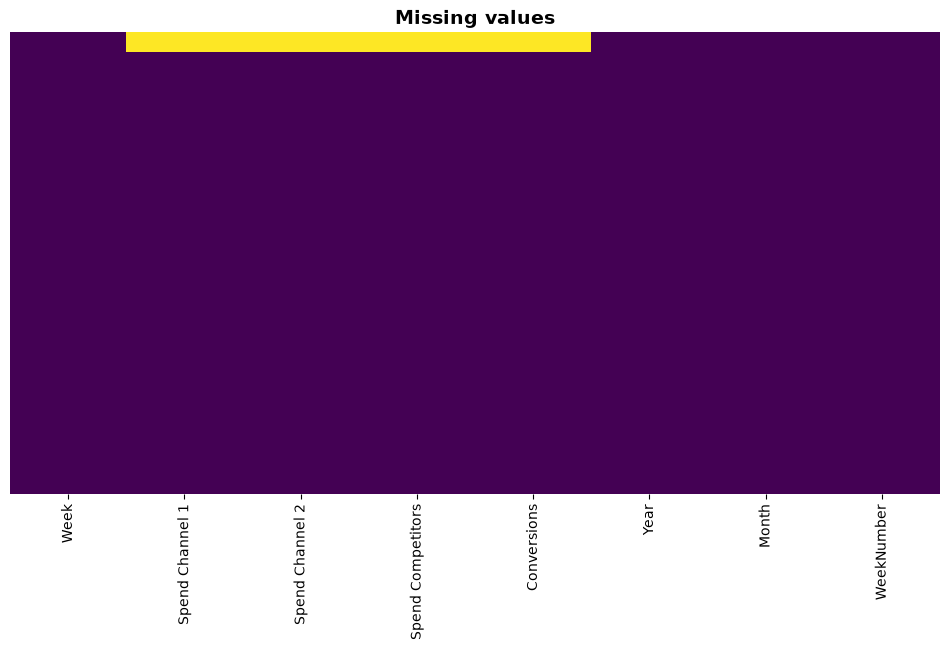

In [9]:
# Se muestra mapa de valores perdidos
plt.figure(figsize=(12, 6))
sns.heatmap(DataEstructura11.isna(), cmap="viridis", cbar=False, yticklabels=False)
plt.title("Missing values", fontsize=14, fontweight='bold')
plt.show()

In [10]:
ResumenNulos = pd.DataFrame({
    "Valores_perdidos": DataEstructura11.isna().sum(),
    "Porcentaje_perdidos": (
        DataEstructura11.isna().mean() * 100
    ).round(2)
}).rename_axis("Columna").reset_index()

ResumenNulos

,Columna,Valores_perdidos,Porcentaje_perdidos
0,Week,0,0.00
1,Spend Channel 1,9,4.31
2,Spend Channel 2,9,4.31
3,Spend Competitors,9,4.31
4,Conversions,9,4.31
5,Year,0,0.00
6,Month,0,0.00
7,WeekNumber,0,0.00


## Show time series


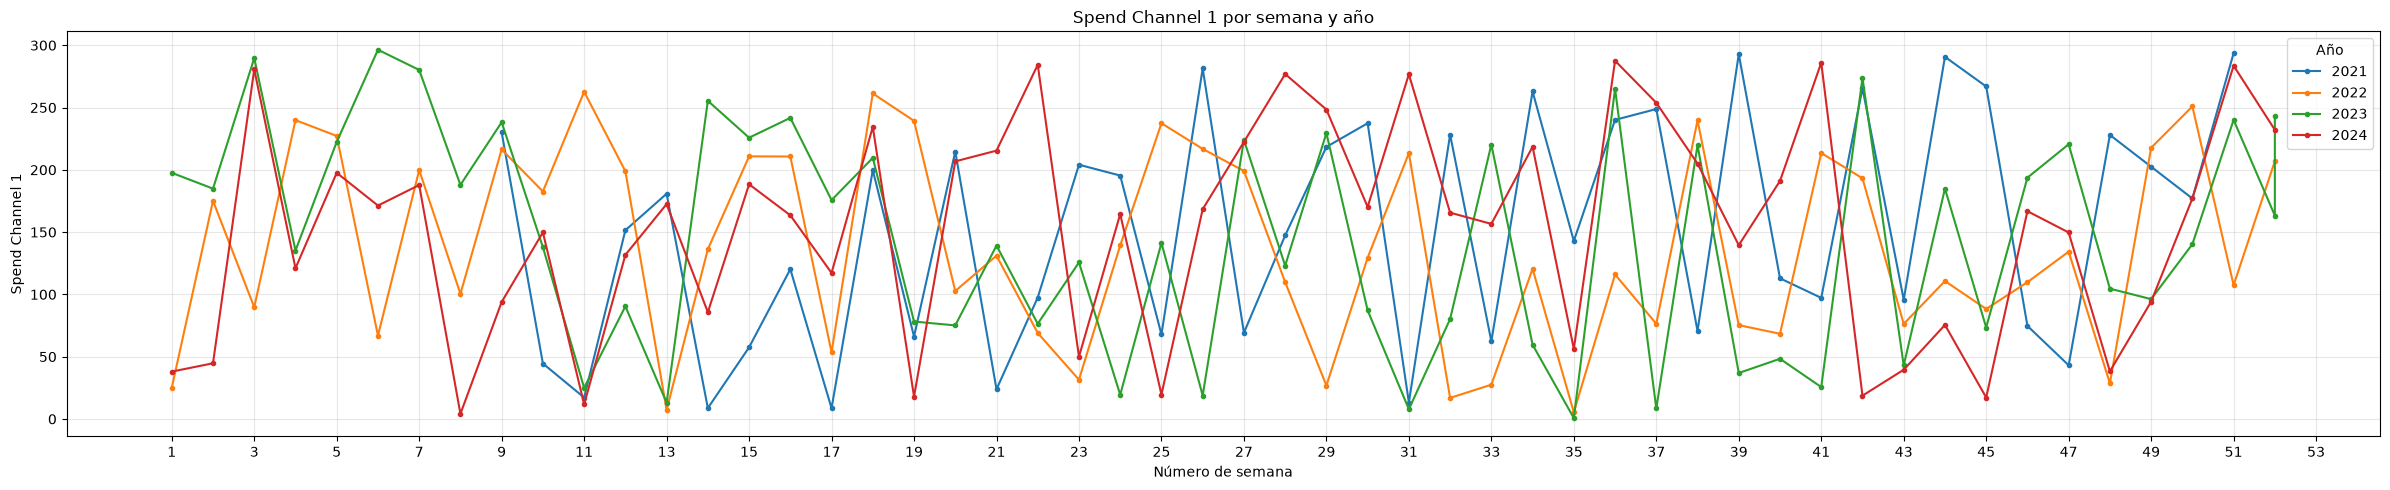

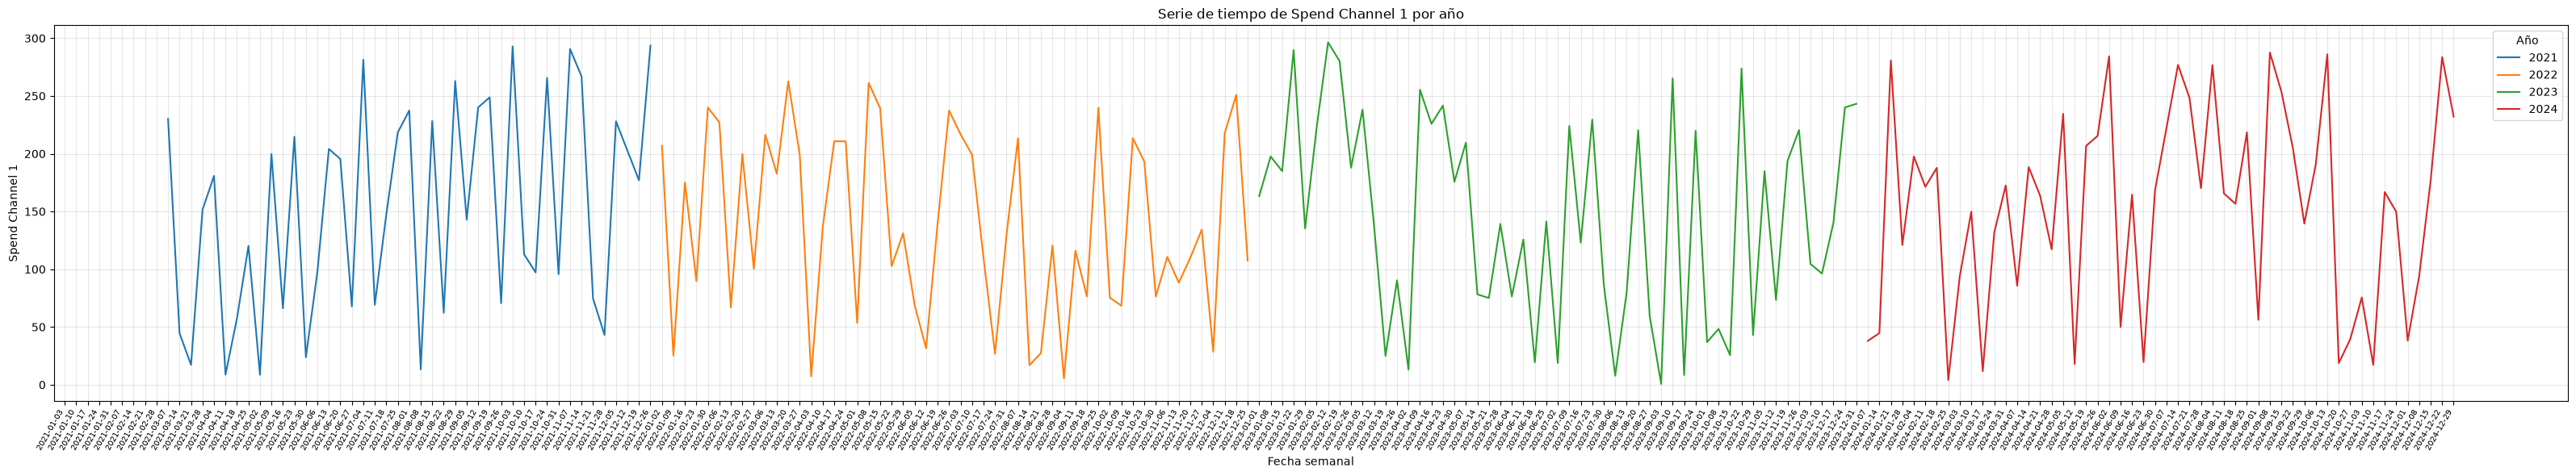

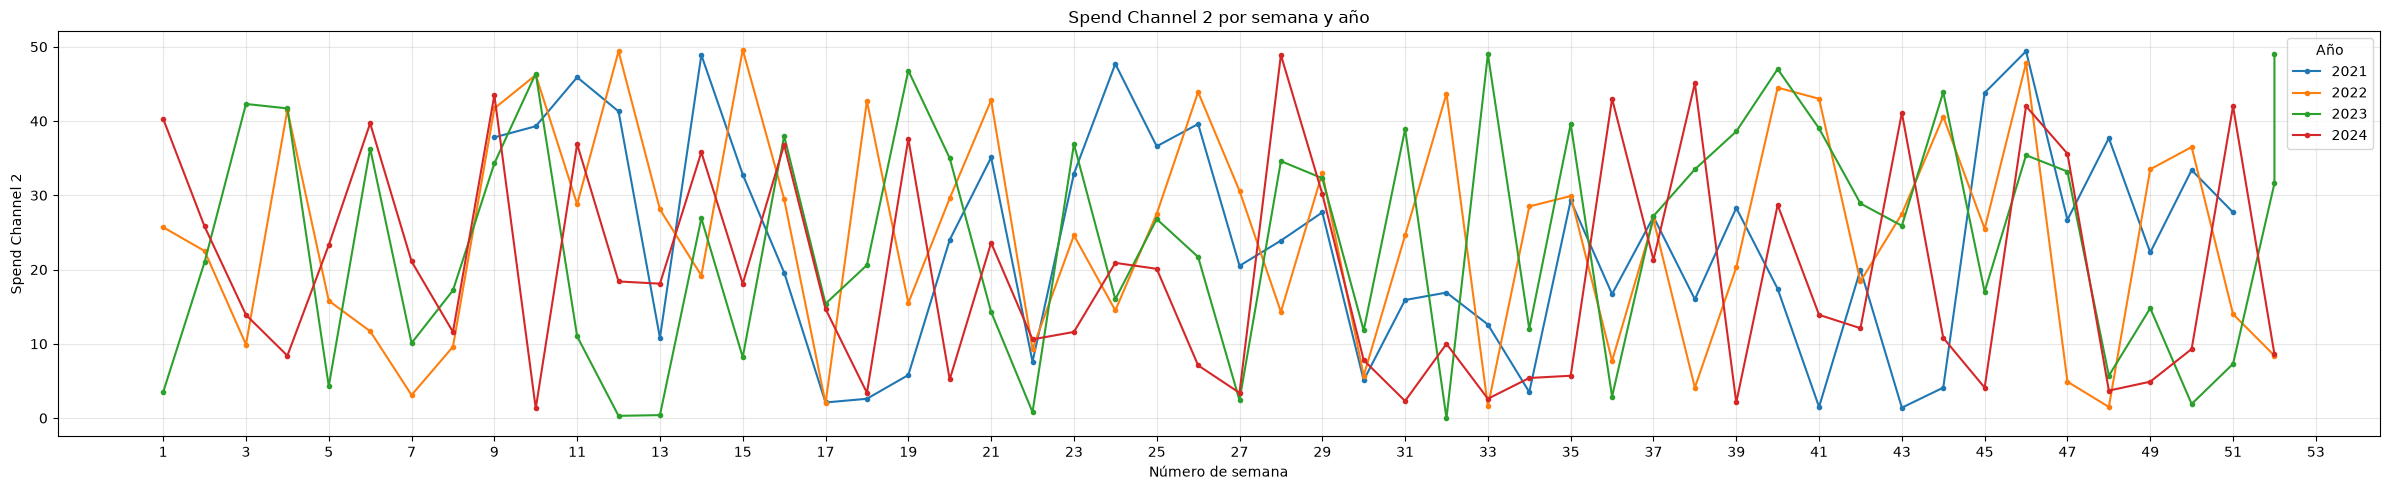

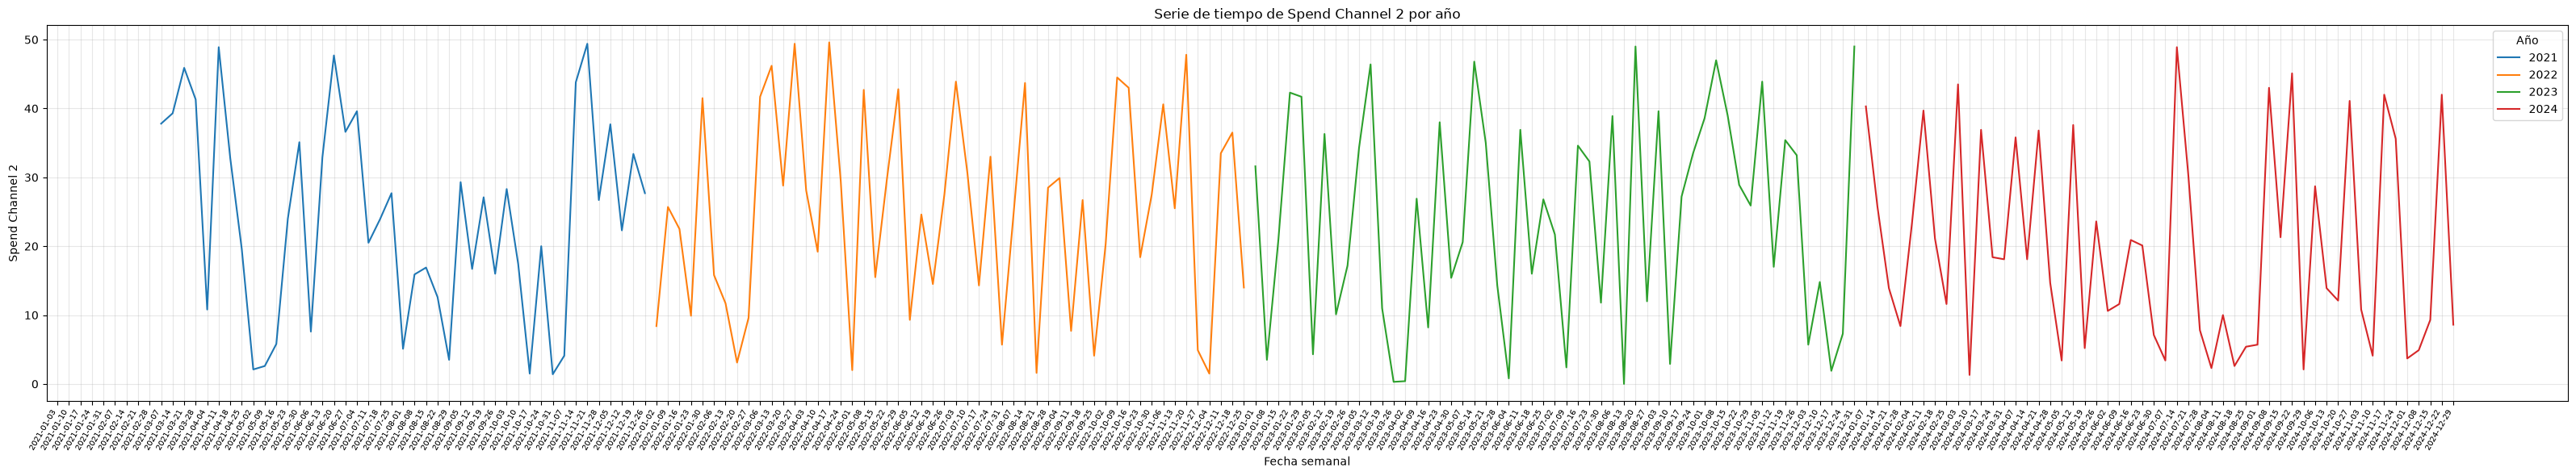

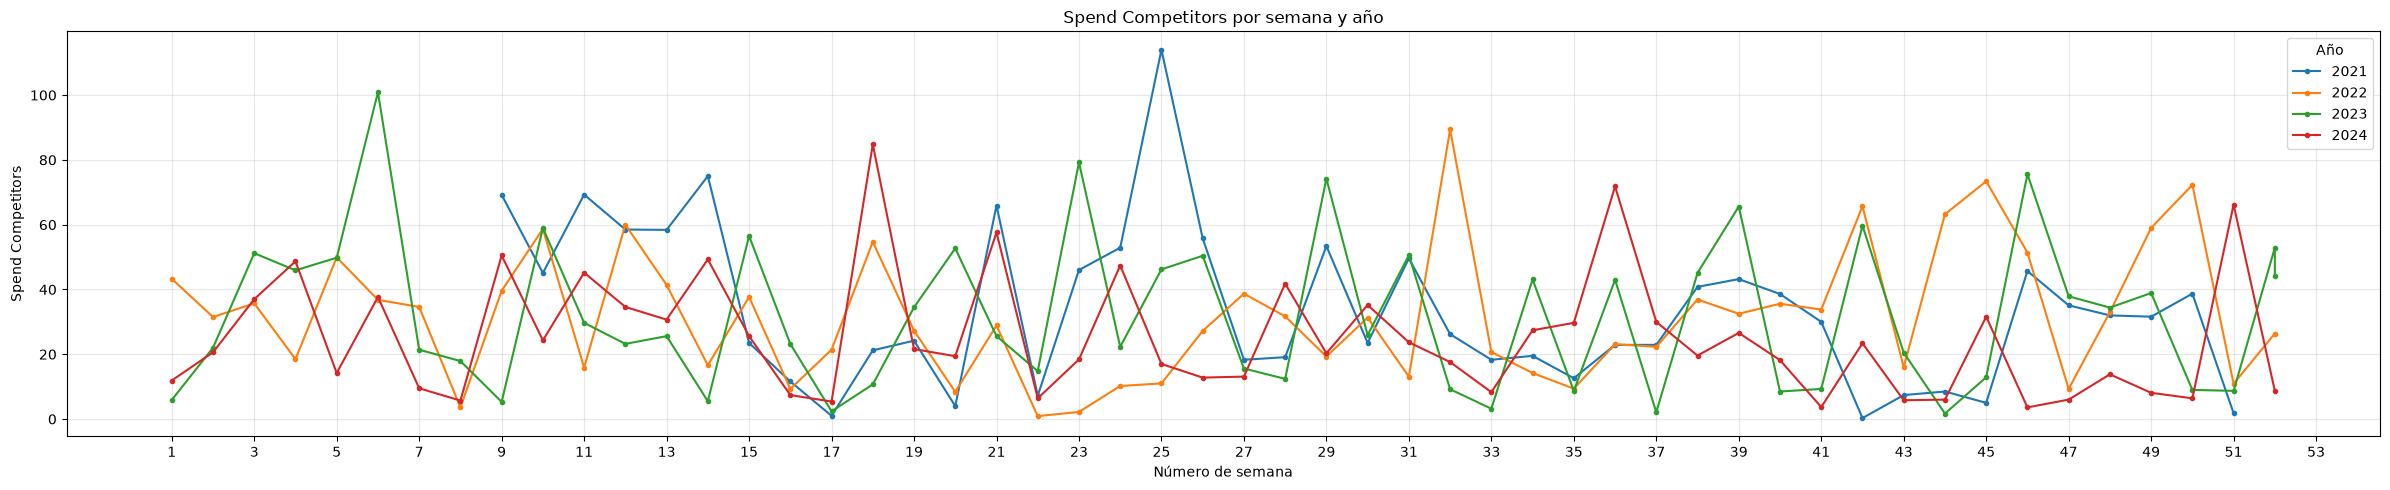

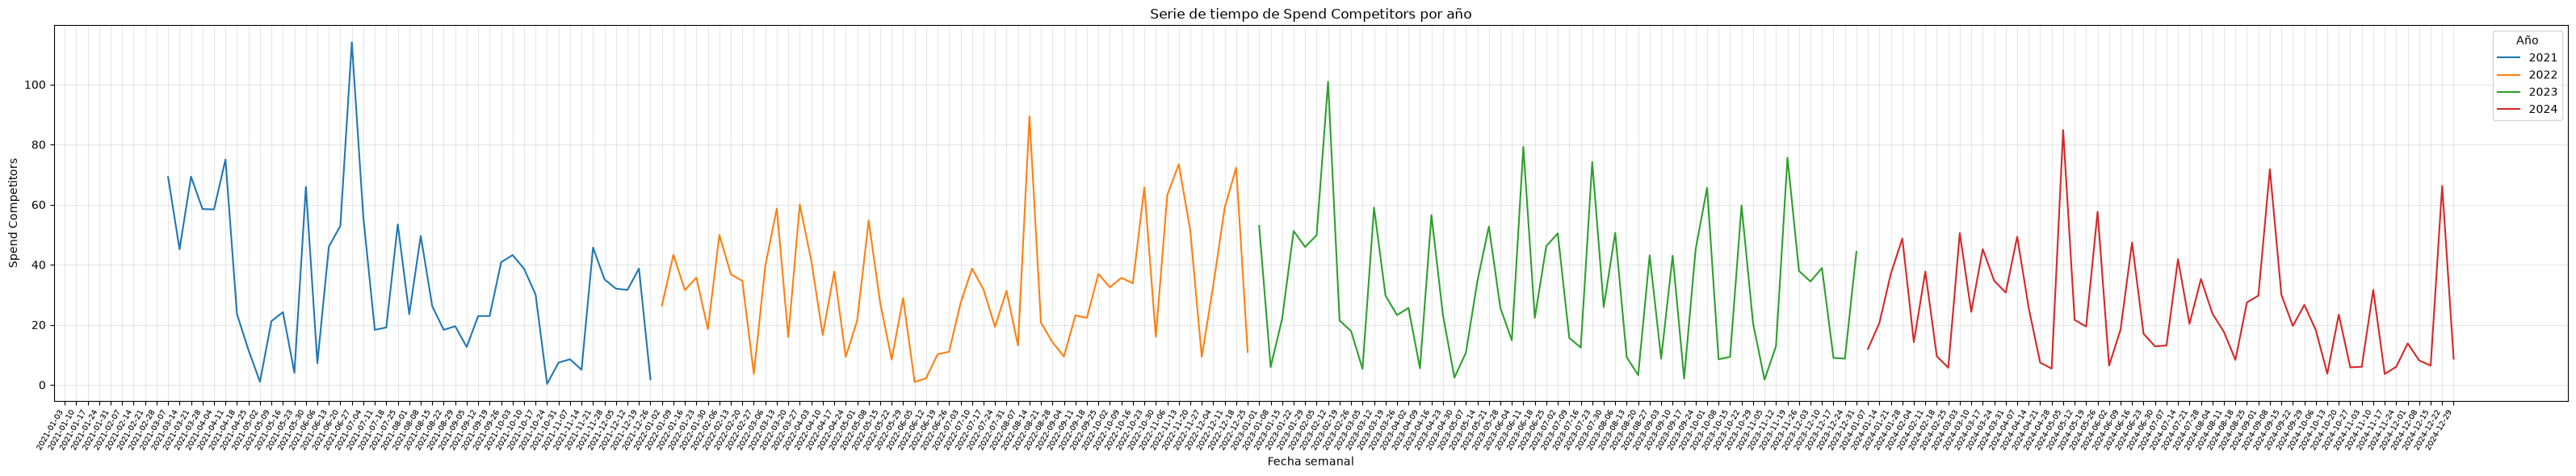

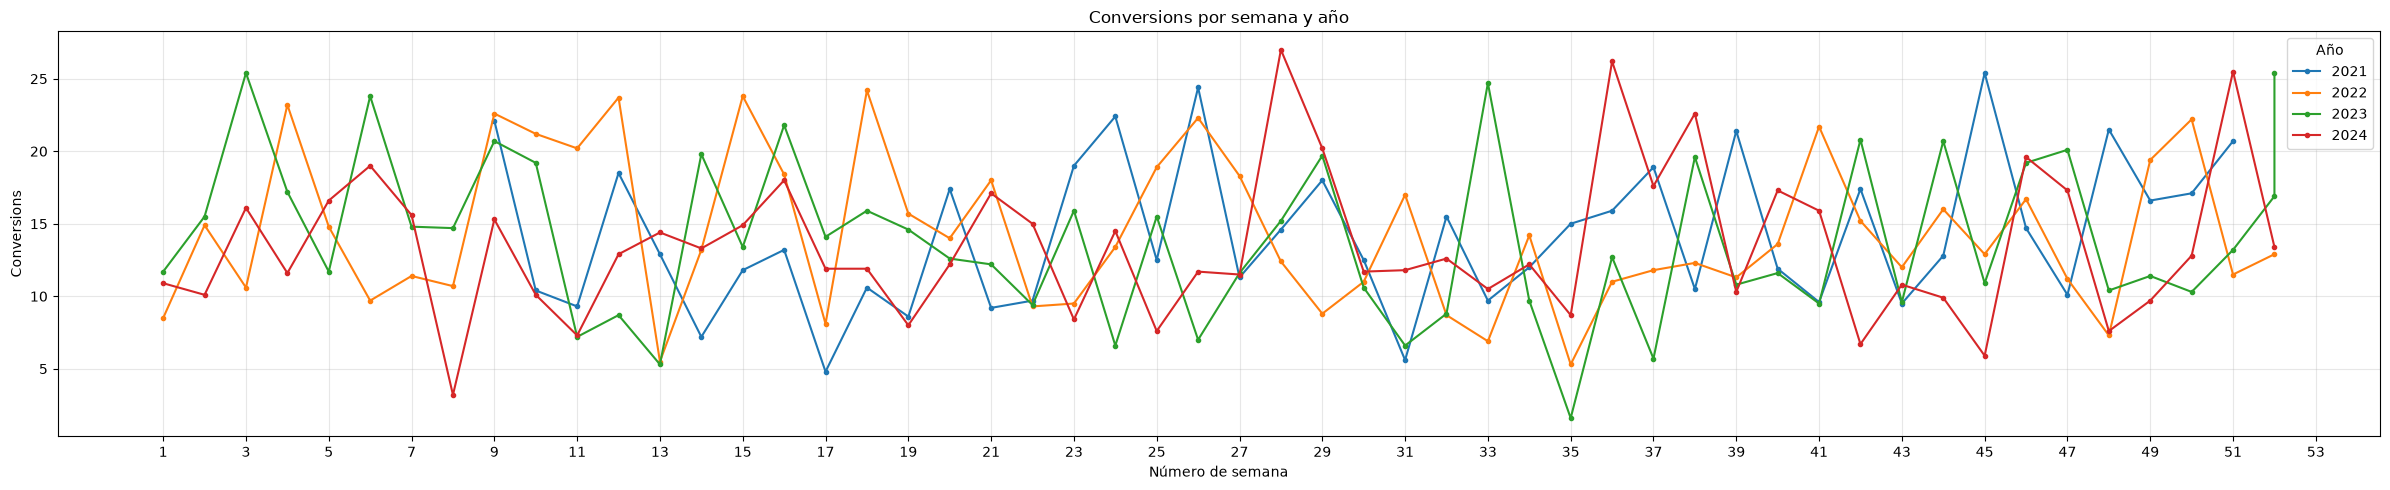

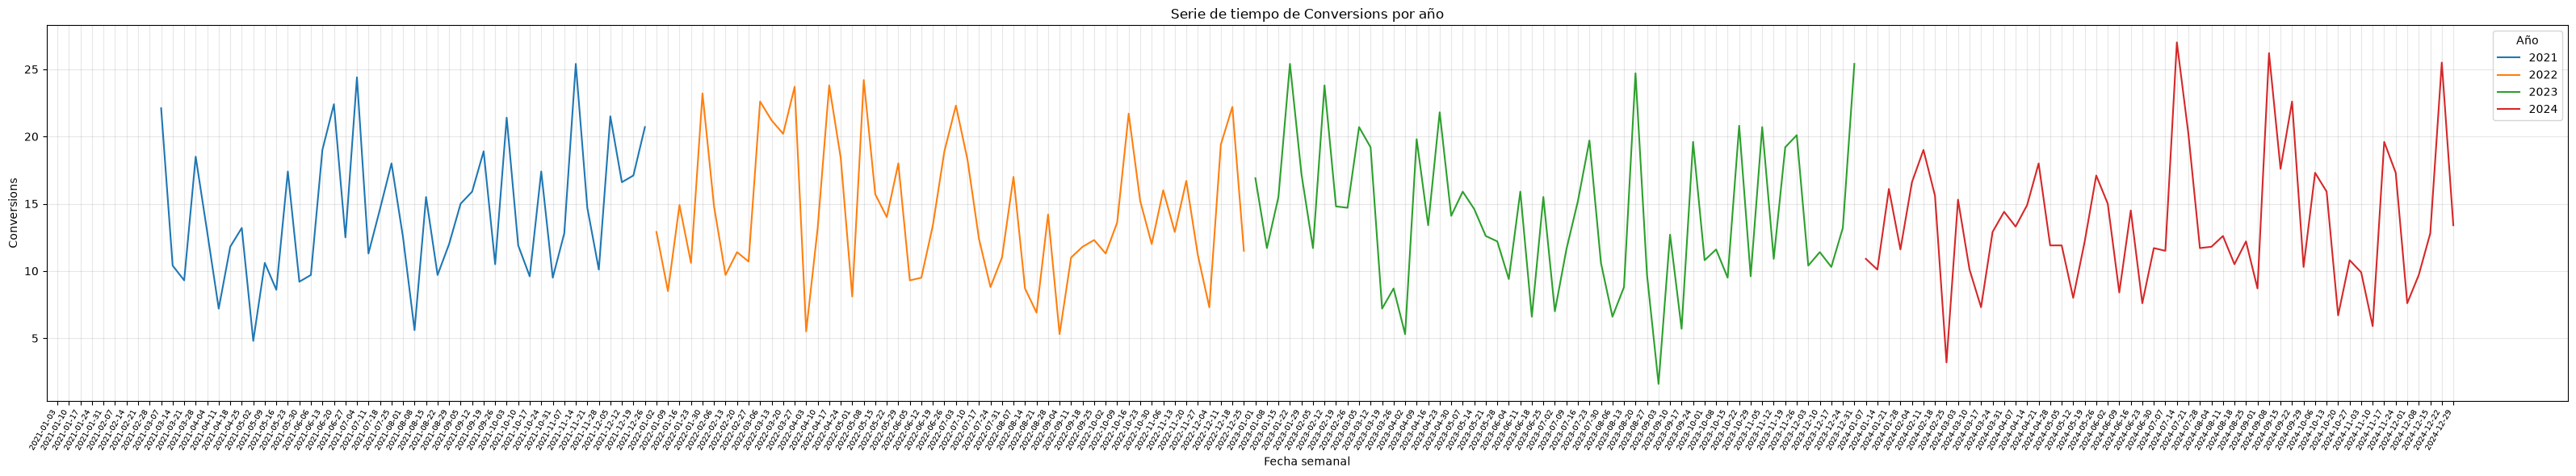

In [ ]:

variables = [
    "Spend Channel 1",
    "Spend Channel 2",
    "Spend Competitors",
    "Conversions"
]

df_plot = (
    DataEstructura11
    .assign(Week=lambda df: pd.to_datetime(df["Week"]))
    .sort_values("Week")
    .copy()
)

df_plot["Year"] = df_plot["Week"].dt.year

# Asignar un mismo color a cada año en todos los gráficos
years = sorted(df_plot["Year"].unique())
colores = dict(zip(
    years,
    sns.color_palette("tab10", n_colors=len(years))
))

for variable in variables:

    # 1. Comparación por número de semana y año
    fig, ax = plt.subplots(figsize=(24, 5))

    for year, datos in df_plot.groupby("Year"):
        datos = datos.sort_values("WeekNumber")

        ax.plot(
            datos["WeekNumber"].to_numpy(dtype=float),
            datos[variable].to_numpy(
                dtype=float, na_value=float("nan")
            ),
            label=str(year),
            color=colores[year],
            linewidth=1.5,
            marker="o",
            markersize=3
        )

    ax.set_title(f"{variable} by week number and year")
    ax.set_xlabel("Número de semana")
    ax.set_ylabel(variable)
    ax.set_xticks(range(1, 54, 2))
    ax.legend(title="Año")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    # 2. Serie de tiempo con fechas semanales
    fig, ax = plt.subplots(figsize=(32, 6))

    for year, datos in df_plot.groupby("Year"):
        ax.plot(
            datos["Week"],
            datos[variable].to_numpy(
                dtype=float, na_value=float("nan")
            ),
            label=str(year),
            color=colores[year],
            linewidth=1.5
        )

    ax.set_xticks(df_plot["Week"])
    ax.set_xticklabels(
        df_plot["Week"].dt.strftime("%Y-%m-%d"),
        rotation=60,
        ha="right",
        fontsize=7
    )

    ax.set_title(f"Serie de tiempo de {variable} por año")
    ax.set_xlabel("Fecha semanal")
    ax.set_ylabel(variable)
    ax.legend(title="Año")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    
    plt.show()